# UMAP der Primärtumoren: Wie ähneln sich die Tumortypen?

**Forschungsfrage:** Wie ähneln sich verschiedene Tumortypen in ihrer Genexpression?

Dieses Notebook baut auf `notebook_pca.ipynb` auf. Eingabe sind die **ersten 50 Hauptkomponenten** der aufbereiteten Primärtumoren
(9.104 Proben). Die Hauptkomponentenanalyse hat gezeigt, welche groben Achsen die Tumortypen trennen; viele Karzinome überlappen dort aber in einer großen Wolke.
Hier fragen wir genauer: **Welche Tumortypen liegen im Einzelnen nah beieinander?** Dafür verwenden wir die Nachbarschaften der Proben und
UMAP (*Uniform Manifold Approximation and Projection*) als nichtlineare Darstellung in zwei Dimensionen.

**Voraussetzung:** `notebook_aufbereitung.ipynb` und `notebook_pca.ipynb` wurden in dieser Reihenfolge einmal ausgeführt.

### Wie UMAP arbeitet

1. **Nachbarschaftsgraph:** Für jede Probe werden ihre $k$ nächsten Nachbarn im Eingaberaum (hier: 50 Hauptkomponenten) bestimmt.
   Jede Verbindung bekommt ein Gewicht: nahe Nachbarn ein hohes, fernere ein kleines. Die Abstände werden dabei pro Probe relativ zu ihrem nächsten Nachbarn gemessen,
   sodass dichte und dünne Bereiche gleich behandelt werden.
2. **Anordnung in zwei Dimensionen:** Die Punkte werden in der Ebene so verschoben, dass dieser Graph möglichst gut nachgebildet wird:
   Verbundene Proben ziehen sich an, nicht verbundene stoßen sich ab (Optimierung mit einem stochastischen Gradientenverfahren).

Die wichtigsten Parameter:

| Parameter | Bedeutung | Standard hier |
|---|---|---|
| `n_neighbors` | Größe der Nachbarschaft $k$: klein betont feine, lokale Struktur, groß eher den Gesamtaufbau | 15 |
| `min_dist` | wie dicht Punkte im Bild zusammenrücken dürfen; klein ergibt kompakte Gruppen. Ändert nur die Anordnung im Bild, nicht den Nachbarschaftsgraph | 0,5 |
| `metric` | Abstandsmaß im Eingaberaum | euklidisch |
| `random_state` | Zufallsstartwert; macht das Ergebnis wiederholbar | 0 |

**Wichtig für unsere Frage:** UMAP erhält vor allem **lokale Nachbarschaften**. Abstände **zwischen** Gruppen und die Größe von Gruppen im Bild sind nicht verlässlich:
Zwei Gruppen, die im Bild weit auseinanderliegen, sind nicht unbedingt unähnlicher als zwei nahe. Ähnlichkeit messen wir deshalb über **Nachbarschaften**,
nicht über Abstände im Bild. Das Bild dient der Anschauung.

## Aufbau

1. Daten laden
2. Welche Tumortypen ähneln sich? Die Nachbarschaft in den 50 Hauptkomponenten
3. UMAP berechnen und darstellen (mit Tumortypen, die in zwei Teile zerfallen)
4. Wie gut gibt das UMAP-Bild die Nachbarschaften wieder?
5. Robustheit: Parameter, Eingabe und Zufallsstartwert
6. Speichern
7. Zusammenfassung und offene Fragen

In [1]:
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")   # Hinweis von tqdm (Fortschrittsbalken), für uns ohne Bedeutung
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import umap

warnings.filterwarnings("ignore", module="umap")           # Hinweis von UMAP: fester Zufallsstartwert schaltet Parallelisierung ab
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.max_colwidth", 120)
DATA_DIR = Path("data/pancanatlas")
SEED = 0

## 1. Daten laden

Die Scores der Hauptkomponenten stammen aus `notebook_pca.ipynb`, die Metadaten der Proben aus `notebook_aufbereitung.ipynb` (gleiche Zeilenreihenfolge).

In [2]:
Z = np.load(DATA_DIR / "pca_scores.npy")                          # Proben × 100 Hauptkomponenten
explained = np.load(DATA_DIR / "pca_erklaerte_varianz.npy")
meta = pd.read_csv(DATA_DIR / "aufbereitet_proben.csv", dtype={"sample_type": str, "center": str, "portion": str})
assert len(meta) == len(Z)
N_PC = 50
Y = Z[:, :N_PC]
study = meta["study"].to_numpy()
n = len(Y)
print(f"{n} Proben, Eingabe: erste {N_PC} Hauptkomponenten ({explained[:N_PC].sum():.0%} der Varianz)")

9104 Proben, Eingabe: erste 50 Hauptkomponenten (73% der Varianz)


### 1.1 Namen und Farben der Tumortypen

Wie im Notebook zur Hauptkomponentenanalyse: deutsche Namen, verwandte Tumortypen nebeneinander, eine feste Farbe pro Tumortyp.

In [3]:
NAME = {                                       # Reihenfolge: verwandte Tumortypen nebeneinander
    "GBM": "Glioblastom", "LGG": "Niedriggradiges Gliom",
    "PCPG": "Phäochromozytom/Paragangliom", "ACC": "Nebennierenrindenkarzinom",
    "UVM": "Uveamelanom (Auge)", "SKCM": "Melanom der Haut",
    "LAML": "Akute myeloische Leukämie", "DLBC": "Diffus großzelliges B-Zell-Lymphom", "THYM": "Thymom",
    "TGCT": "Keimzelltumor des Hodens",
    "KIRC": "Klarzelliges Nierenzellkarzinom", "KIRP": "Papilläres Nierenzellkarzinom", "KICH": "Chromophobes Nierenzellkarzinom",
    "LIHC": "Leberzellkarzinom", "CHOL": "Gallengangskarzinom", "PAAD": "Pankreaskarzinom",
    "STAD": "Magenkarzinom", "ESCA": "Speiseröhrenkarzinom", "COAD": "Dickdarmkarzinom", "READ": "Mastdarmkarzinom",
    "HNSC": "Plattenepithelkarzinom Kopf-Hals", "LUSC": "Plattenepithelkarzinom Lunge", "CESC": "Gebärmutterhalskarzinom",
    "BLCA": "Harnblasenkarzinom", "LUAD": "Adenokarzinom Lunge", "MESO": "Mesotheliom",
    "THCA": "Schilddrüsenkarzinom", "PRAD": "Prostatakarzinom", "BRCA": "Brustkrebs",
    "OV": "Eierstockkarzinom", "UCEC": "Endometriumkarzinom (Gebärmutter)", "UCS": "Karzinosarkom der Gebärmutter",
    "SARC": "Sarkom (Weichgewebe)",
}
TYPES = list(NAME)
assert set(study) == set(TYPES)
palette = list(plt.cm.tab20.colors) + list(plt.cm.tab20b.colors[::2]) + list(plt.cm.Dark2.colors[:3])   # 33 Farben
color = dict(zip(TYPES, palette))

## 2. Welche Tumortypen ähneln sich? Die Nachbarschaft in den 50 Hauptkomponenten

UMAP baut sein Bild aus den **15 nächsten Nachbarn** jeder Probe in den 50 Hauptkomponenten. Diese Nachbarschaft werten wir zuerst direkt aus:
Für jede Probe fragen wir, aus welchen Tumortypen ihre 15 nächsten Nachbarn stammen (euklidischer Abstand).
Für jedes Paar von Tumortypen A und B ergibt das den Anteil der Nachbarn von A-Proben, die zu B gehören.

- Ein hoher Anteil **im eigenen Typ** heißt: Der Tumortyp ist klar von den anderen abgegrenzt.
- Ein hoher Anteil **in einem anderen Typ** heißt: Die beiden Typen ähneln sich in ihrer Genexpression.

Die Abstände berechnen wir blockweise über $\lVert a - b \rVert^2 = \lVert a \rVert^2 - 2\, a^\top b + \lVert b \rVert^2$; so passt die Rechnung in den Speicher
(9.104 $\times$ 9.104 Abstände auf einmal wären 330 Megabyte).

In [4]:
K = 15

def nachbarn(Y, K=K, block=2000):
    Y = np.asarray(Y, dtype=np.float32)
    sq = (Y**2).sum(axis=1)
    nb = np.empty((len(Y), K), dtype=np.int64)
    for s in range(0, len(Y), block):
        d2 = sq[s:s + block, None] - 2 * Y[s:s + block] @ Y.T + sq[None, :]
        d2[np.arange(d2.shape[0]), np.arange(s, s + d2.shape[0])] = np.inf      # sich selbst ausschließen
        nb[s:s + block] = np.argpartition(d2, K, axis=1)[:, :K]
    return nb

def paare(nb):
    # Zeile A, Spalte B: Anteil der Nachbarn von A-Proben, die zu Tumortyp B gehören
    t = pd.crosstab(np.repeat(study, nb.shape[1]), study[nb.ravel()], normalize="index")
    t.index.name, t.columns.name = "Tumortyp", "Nachbar-Tumortyp"
    return t.loc[TYPES, TYPES]

def eigener_anteil(nb):
    return pd.Series((study[nb] == study[:, None]).mean(axis=1)).groupby(study).mean().loc[TYPES]

nb_pca = nachbarn(Y)
paare_pca = paare(nb_pca)
eigen_pca = eigener_anteil(nb_pca)
print(f"Anteil der Nachbarn aus demselben Tumortyp: im Mittel über die Tumortypen {eigen_pca.mean():.1%}")
print(eigen_pca.sort_values().head(8).map("{:.0%}".format).rename("Anteil eigener Typ").to_frame().T)

lang = paare_pca.stack().rename("Anteil").reset_index()
lang = lang[(lang["Tumortyp"] != lang["Nachbar-Tumortyp"]) & (lang["Anteil"] >= 0.05)].sort_values("Anteil", ascending=False)
lang.assign(Name=lang["Tumortyp"].map(NAME), **{"Name Nachbar": lang["Nachbar-Tumortyp"].map(NAME)},
            Anteil=lang["Anteil"].map("{:.0%}".format)).reset_index(drop=True)

Anteil der Nachbarn aus demselben Tumortyp: im Mittel über die Tumortypen 84.1%
                   READ ESCA CHOL  UCS COAD CESC  GBM UCEC
Anteil eigener Typ  29%  37%  52%  53%  72%  74%  75%  78%


,Tumortyp,Nachbar-Tumortyp,Anteil,Name,Name Nachbar
0,READ,COAD,69%,Mastdarmkarzinom,Dickdarmkarzinom
1,CHOL,LIHC,32%,Gallengangskarzinom,Leberzellkarzinom
2,ESCA,STAD,28%,Speiseröhrenkarzinom,Magenkarzinom
3,GBM,LGG,23%,Glioblastom,Niedriggradiges Gliom
4,COAD,READ,22%,Dickdarmkarzinom,Mastdarmkarzinom
5,UCS,UCEC,20%,Karzinosarkom der Gebärmutter,Endometriumkarzinom (Gebärmutter)
6,ESCA,HNSC,17%,Speiseröhrenkarzinom,Plattenepithelkarzinom Kopf-Hals
7,STAD,ESCA,12%,Magenkarzinom,Speiseröhrenkarzinom
8,KICH,KIRC,12%,Chromophobes Nierenzellkarzinom,Klarzelliges Nierenzellkarzinom
9,ESCA,LUSC,10%,Speiseröhrenkarzinom,Plattenepithelkarzinom Lunge


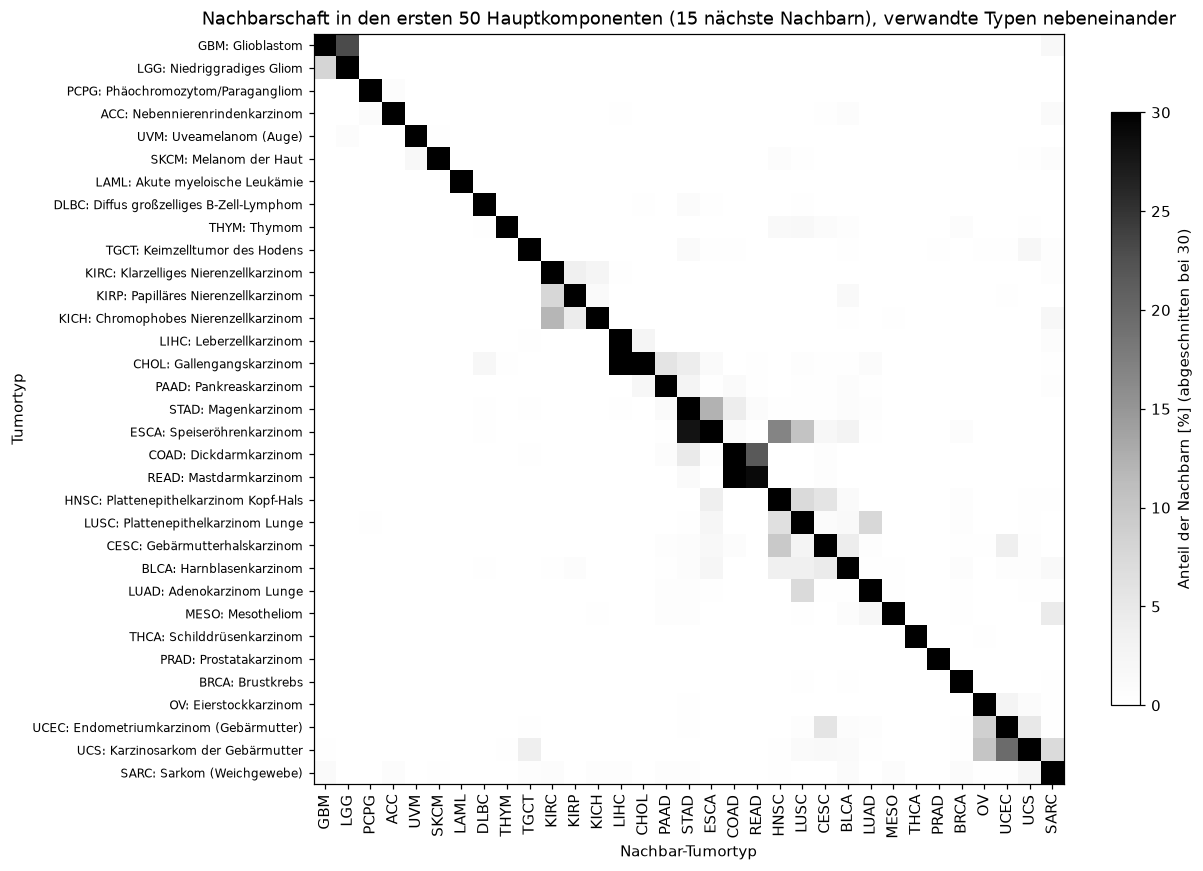

In [5]:
def heatmap(t, titel):
    fig, ax = plt.subplots(figsize=(11, 10))
    im = ax.imshow(t * 100, cmap="Greys", vmax=30)
    ax.set_xticks(range(len(TYPES)), TYPES, rotation=90)
    ax.set_yticks(range(len(TYPES)), [f"{s}: {NAME[s]}" for s in TYPES], fontsize=8)
    ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.7, label="Anteil der Nachbarn [%] (abgeschnitten bei 30)")
    ax.set(title=titel, xlabel="Nachbar-Tumortyp", ylabel="Tumortyp")
    plt.show()

heatmap(paare_pca, f"Nachbarschaft in den ersten {N_PC} Hauptkomponenten ({K} nächste Nachbarn), verwandte Typen nebeneinander")

**Beobachtungen:**
- **Die meisten Tumortypen sind klar voneinander abgegrenzt:** Im Mittel stammen 84 % der Nachbarn aus demselben Tumortyp.
- **Deutlich weniger eigenständig** sind Mastdarmkrebs (READ, 29 %), Speiseröhrenkrebs (ESCA, 37 %), Gallengangkrebs (CHOL, 52 %) und das Karzinosarkom der Gebärmutter (UCS, 53 %).
  Das sind die Tumortypen, die anderen am stärksten ähneln.
- **Ähnliche Tumortypen**, also Paare mit hohem Nachbaranteil, lassen sich in drei Arten einteilen (Anteil der Nachbarn in Klammern):

| Art | Tumortypen | naheliegende Erklärung |
|---|---|---|
| gleiches Organ | Mastdarm → Dickdarm (READ → COAD, 69 %; umgekehrt 22 %) | Mast- und Dickdarm: praktisch derselbe Tumor |
| | Glioblastom → niedriggradiges Gliom (GBM → LGG, 23 %; umgekehrt 8 %), chromophobes/papilläres → klarzelliges Nierenzellkarzinom (KICH, KIRP → KIRC, 12 % bzw. 8 %), Lunge Adeno ↔ Plattenepithel (LUAD ↔ LUSC, 7 % bzw. 8 %), Karzinosarkom → Endometriumkarzinom (UCS → UCEC, 20 %) | Untertypen eines Organs, die sich teilweise überlappen |
| verschiedene Organe, gleicher Gewebetyp | Speiseröhre → Kopf-Hals (17 %) und Lunge-Plattenepithel (10 %), Gebärmutterhals → Kopf-Hals (10 %), Kopf-Hals ↔ Lunge-Plattenepithel (7 % bzw. 6 %) | Plattenepithelkarzinome |
| | Speiseröhre ↔ Magen (ESCA ↔ STAD, 28 % bzw. 12 %) | Adenokarzinome des oberen Verdauungstrakts |
| verschiedene Organe, gemeinsame Herkunft | Gallengang → Leber (CHOL → LIHC, 32 %) und Bauchspeicheldrüse (6 %) | Leber, Gallengang und Bauchspeicheldrüse entstehen aus derselben Anlage; Gallengangstumoren liegen oft in der Leber |
| | Karzinosarkom → Eierstock (10 %) und Sarkom (7 %), Endometrium → Eierstock (9 %) und Gebärmutterhals (6 %) | gynäkologische Tumoren (aus dem Müller-Gang); Karzinosarkome enthalten Bindegewebe |

- **Speiseröhrenkrebs** ähnelt **zwei verschiedenen Gruppen**: dem Magenkrebs (28 %) **und** den Plattenepithelkarzinomen (Kopf-Hals 17 %, Lunge 10 %). Abschnitt 3.1 klärt, warum.
- Die Anteile sind **nicht symmetrisch**: Kleine Tumortypen (Mastdarm, Gallengang, Karzinosarkom, Speiseröhre) haben viele Nachbarn in großen Typen, umgekehrt kaum.
  Das liegt zum Teil einfach an den Gruppengrößen.

## 3. UMAP berechnen und darstellen

Wir rechnen UMAP mit den Standardparametern aus der Tabelle oben. Für `min_dist` nehmen wir 0,5 statt des Voreinstellungswerts 0,1:
Mit 0,1 schrumpfen viele Tumortypen zu kleinen Punkten, und die Struktur innerhalb der Gruppen ist nicht mehr zu sehen (Vergleich in Abschnitt 5.1). Eine Rechnung dauert je nach Rechner etwa 20 bis 60 Sekunden
(beim ersten Aufruf zusätzlich einige Sekunden, weil UMAP seinen Code einmalig übersetzt).

In [6]:
STANDARD = dict(n_neighbors=15, min_dist=0.5, metric="euclidean", random_state=SEED)

def umap_2d(daten, **param):
    return umap.UMAP(n_components=2, **{**STANDARD, **param}).fit_transform(daten)

E = umap_2d(Y)
print("Einbettung:", E.shape)

Einbettung: (9104, 2)


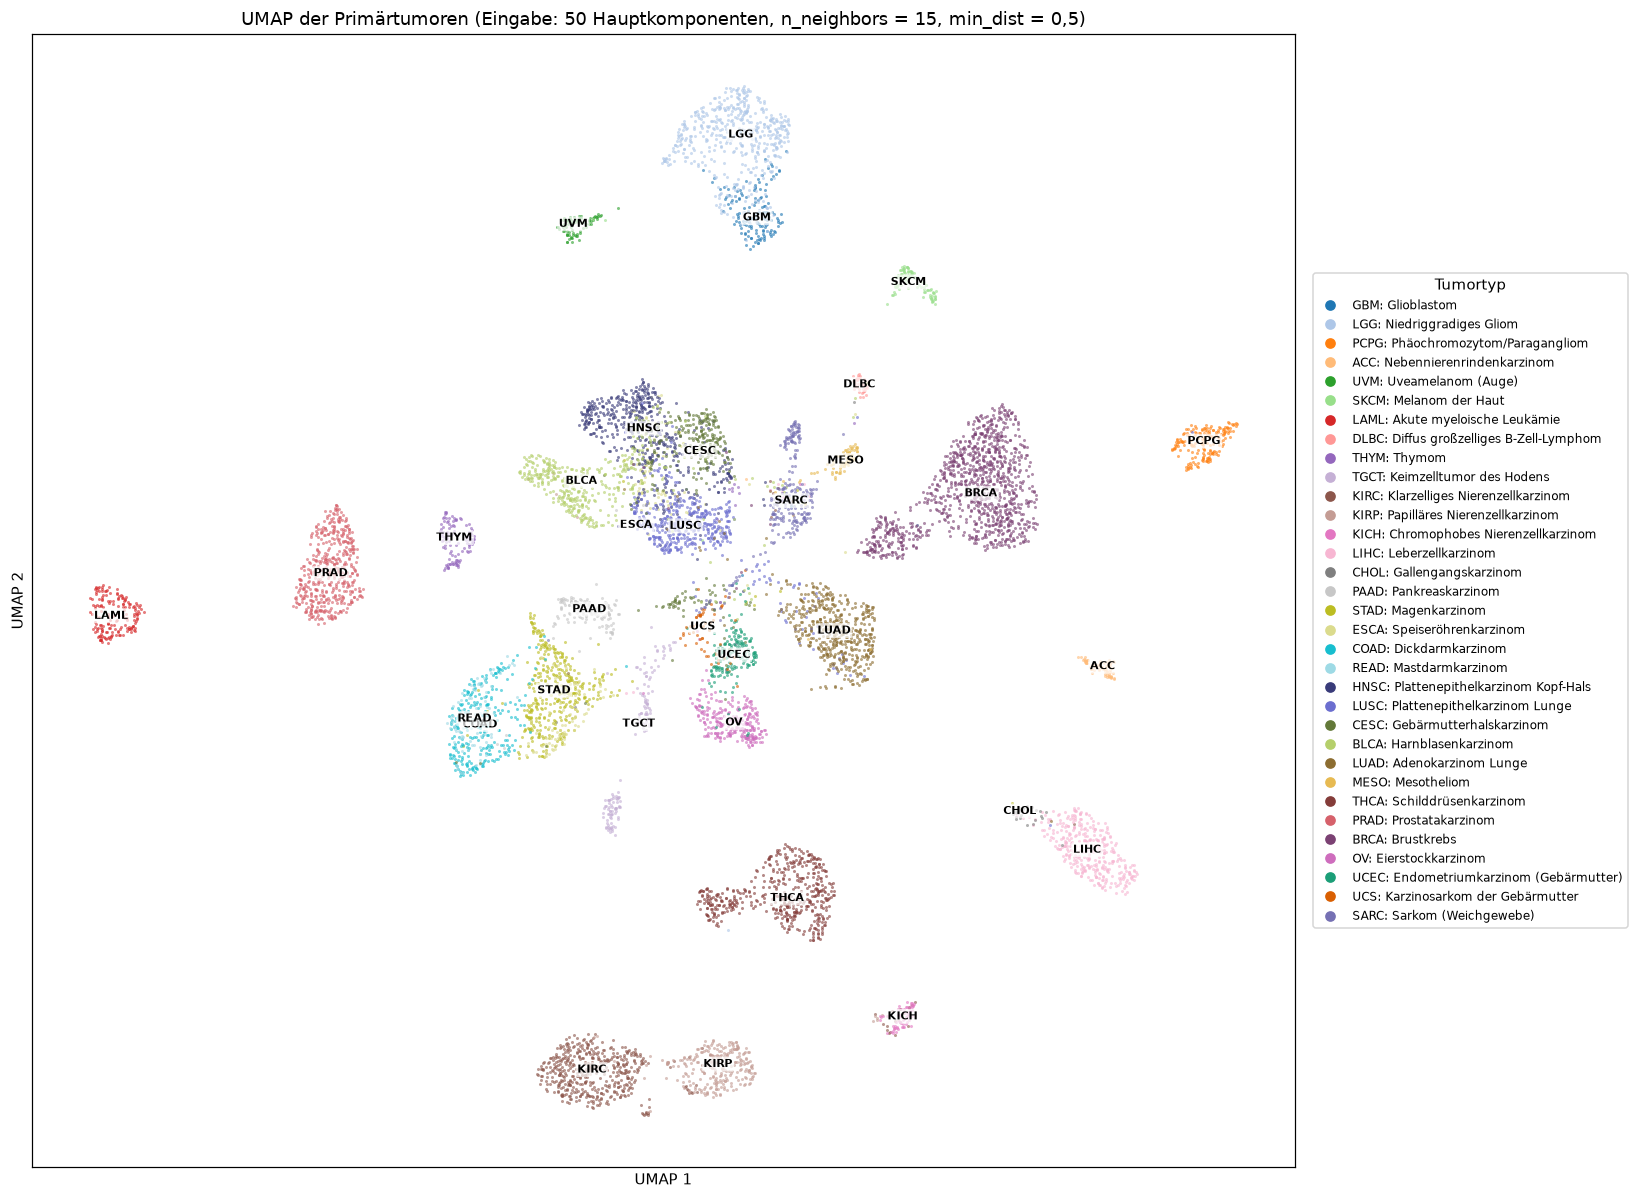

In [7]:
def umap_bild(ax, E, titel, beschriften=True, s=3):
    for t in TYPES:
        m = study == t
        ax.scatter(E[m, 0], E[m, 1], s=s, alpha=0.6, color=color[t], linewidths=0)
        if beschriften:
            x, y = np.median(E[m], axis=0)
            ax.annotate(t, (x, y), fontsize=7.5, ha="center", va="center", fontweight="bold",
                        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.7))
    ax.set(title=titel, xticks=[], yticks=[], xlabel="UMAP 1", ylabel="UMAP 2")

fig, ax = plt.subplots(figsize=(15, 11))
umap_bild(ax, E, f"UMAP der Primärtumoren (Eingabe: {N_PC} Hauptkomponenten, n_neighbors = 15, min_dist = 0,5)", s=4)
handles = [plt.Line2D([], [], marker="o", ls="", ms=6, color=color[t], label=f"{t}: {NAME[t]}") for t in TYPES]
ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8, title="Tumortyp")
plt.tight_layout()
plt.show()

Die Achsen eines UMAP-Bildes haben keine Bedeutung (anders als Hauptkomponenten); deshalb fehlen die Zahlen an den Achsen.
Die Beschriftung steht jeweils am Median der Proben eines Tumortyps.

**Beobachtungen:**
- Das Bild zeigt dieselbe Struktur wie die Nachbarschaftstabelle, aber auf einen Blick. **Abseits** liegen Tumortypen mit eigenem Gewebe:
  akute myeloische Leukämie, Prostata, Thymom, Leber (mit dem Gallengang am Rand), die Nieren (klarzellig und papillär nebeneinander, chromophob getrennt),
  Schilddrüse, Phäochromozytom/Paragangliom, Nebennierenrinde, die beiden Melanome und die Hirntumoren (niedriggradiges Gliom und Glioblastom ineinander übergehend).
- In der **Mitte** liegen die Karzinome dicht beieinander, aber in erkennbaren Gruppen:
  die **Plattenepithelkarzinome** (Kopf-Hals, Lunge, Gebärmutterhals, Teile der Speiseröhre, daneben die Harnblase),
  der **Verdauungstrakt** (Magen, Dick- und Mastdarm ineinander, daneben die Bauchspeicheldrüse) und die **gynäkologischen Tumoren** (Endometrium, Karzinosarkom, Eierstock).
- Die Karzinom-Wolke aus der Hauptkomponentenanalyse ist damit deutlich aufgelöst: UMAP zeigt in zwei Dimensionen, was dort auf viele Achsen verteilt war.
- Einige Tumortypen **zerfallen in zwei Teile** (Speiseröhre, Gebärmutterhals, Brustkrebs, Schilddrüse, Hodentumoren, Sarkom). Das untersucht der nächste Abschnitt.

### 3.1 Tumortypen, die im Bild in zwei Teile zerfallen

Einige Tumortypen bilden im Bild zwei getrennte Teile, zum Beispiel Speiseröhrenkrebs (ESCA), Gebärmutterhalskrebs (CESC), Brustkrebs (BRCA) und Schilddrüsenkarzinom (THCA).
Steckt dahinter Biologie? Wir teilen die Proben eines Tumortyps mit $k$-Means ($k = 2$) anhand ihrer Lage im Bild in zwei Teile und vergleichen die Teile
mit dem **histologischen Typ** aus der klinischen Tabelle (Spalte `histological_type`, die feingewebliche Einordnung durch die Pathologie).
Beim Brustkrebs vergleichen wir zusätzlich die Expression von `ESR1` (Östrogenrezeptor 1).

Das ist eine Erkundung, kein Clustering-Ergebnis: Die Zahl der Teile ist mit 2 vorgegeben, und die Lage im Bild hängt von den UMAP-Parametern ab.

In [8]:
from scipy.cluster.vq import kmeans2
from IPython.display import display

cdr = pd.read_excel(DATA_DIR / "TCGA-CDR-SupplementalTableS1.xlsx", sheet_name="TCGA-CDR").set_index("bcr_patient_barcode")
histologie = meta["patient"].map(cdr["histological_type"]).astype(str).replace({"nan": "ohne Angabe", "[Not Available]": "ohne Angabe"}).to_numpy()
genes = pd.read_csv(DATA_DIR / "aufbereitet_gene.csv")
X_gene = np.load(DATA_DIR / "aufbereitet_matrix.npy", mmap_mode="r")
esr1 = np.asarray(X_gene[:, genes.index[genes["name"] == "ESR1"][0]])      # log2-Expression, zentriert

def zwei_teile(t):
    idx = np.where(study == t)[0]
    _, teil = kmeans2(E[idx].astype(np.float64), 2, seed=SEED, minit="++")
    teil = np.where(teil == np.bincount(teil).argmax(), "größerer Teil", "kleinerer Teil")   # einheitliche Benennung
    return idx, teil

teile = {}
for t in ["ESCA", "CESC", "BRCA", "THCA", "TGCT", "SARC"]:
    idx, teil = zwei_teile(t)
    teile[t] = (idx, teil)
    tab = pd.crosstab(pd.Series(histologie[idx], name="histologischer Typ").str.slice(0, 70), pd.Series(teil, name=f"{t}: {NAME[t]}"))
    tab = tab.loc[tab.sum(axis=1).sort_values(ascending=False).index]
    display(tab.head(6))
idx, teil = teile["BRCA"]
print("Brustkrebs, mittlere ESR1-Expression (log2, zentriert):",
      {k: round(float(esr1[idx][teil == k].mean()), 2) for k in ["größerer Teil", "kleinerer Teil"]})

ESCA: Speiseröhrenkarzinom,größerer Teil,kleinerer Teil
histologischer Typ,,
Esophagus Squamous Cell Carcinoma,94,0
"Esophagus Adenocarcinoma, NOS",1,87


CESC: Gebärmutterhalskarzinom,größerer Teil,kleinerer Teil
histologischer Typ,,
Cervical Squamous Cell Carcinoma,229,22
Endocervical Type of Adenocarcinoma,1,19
Mucinous Adenocarcinoma of Endocervical Type,0,17
Endocervical Adenocarcinoma of the Usual Type,1,5
Adenosquamous,1,3
Endometrioid Adenocarcinoma of Endocervix,0,3


BRCA: Brustkrebs,größerer Teil,kleinerer Teil
histologischer Typ,,
Infiltrating Ductal Carcinoma,595,179
Infiltrating Lobular Carcinoma,199,2
"Other, specify",35,10
Mixed Histology (please specify),27,2
Mucinous Carcinoma,17,0
Metaplastic Carcinoma,1,7


THCA: Schilddrüsenkarzinom,größerer Teil,kleinerer Teil
histologischer Typ,,
Thyroid Papillary Carcinoma - Classical/usual,300,55
Thyroid Papillary Carcinoma - Follicular (>= 99% follicular patterned),23,79
Thyroid Papillary Carcinoma - Tall Cell (>= 50% tall cell features),35,0
"Other, specify",5,3


TGCT: Keimzelltumor des Hodens,größerer Teil,kleinerer Teil
histologischer Typ,,
Seminoma; NOS,1,62
Non-Seminoma; Embryonal Carcinoma,15,0
Non-Seminoma; Teratoma (Mature)|Non-Seminoma; Teratoma (Immature)|Non-,8,0
Non-Seminoma; Embryonal Carcinoma|Non-Seminoma; Yolk Sac Tumor,6,0
Non-Seminoma; Embryonal Carcinoma|Non-Seminoma; Yolk Sac Tumor|Non-Sem,4,0
Non-Seminoma; Yolk Sac Tumor,3,0


SARC: Sarkom (Weichgewebe),größerer Teil,kleinerer Teil
histologischer Typ,,
Leiomyosarcoma (LMS),30,70
Dedifferentiated liposarcoma,56,1
Pleomorphic 'MFH' / Undifferentiated pleomorphic sarcoma,28,1
Myxofibrosarcoma,24,1
Undifferentiated Pleomorphic Sarcoma (UPS),21,0
Malignant Peripheral Nerve Sheath Tumors (MPNST),7,2


Brustkrebs, mittlere ESR1-Expression (log2, zentriert): {'größerer Teil': 6.19, 'kleinerer Teil': -0.18}


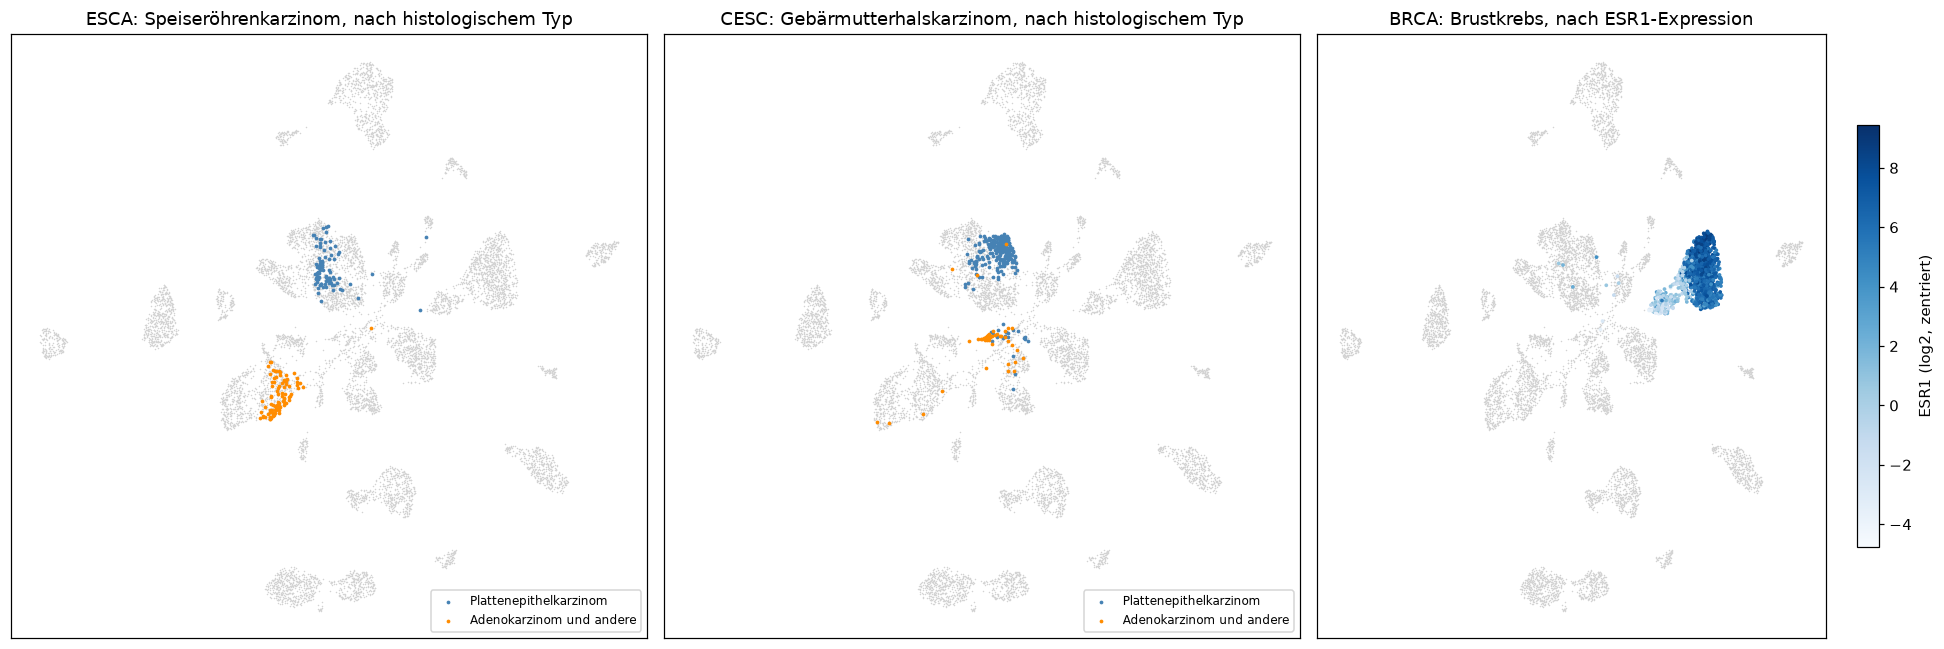

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, t in zip(axes[:2], ["ESCA", "CESC"]):
    m = study == t
    ax.scatter(E[~m, 0], E[~m, 1], s=1, color="lightgray", linewidths=0)
    platten = np.char.find(histologie.astype(str), "Squamous") >= 0
    for maske, farbe, name in [(m & platten, "steelblue", "Plattenepithelkarzinom"), (m & ~platten, "darkorange", "Adenokarzinom und andere")]:
        ax.scatter(E[maske, 0], E[maske, 1], s=6, color=farbe, label=name, linewidths=0)
    ax.set(title=f"{t}: {NAME[t]}, nach histologischem Typ", xticks=[], yticks=[])
    ax.legend(fontsize=8, loc="lower right")
m = study == "BRCA"
axes[2].scatter(E[~m, 0], E[~m, 1], s=1, color="lightgray", linewidths=0)
sc = axes[2].scatter(E[m, 0], E[m, 1], s=6, c=esr1[m], cmap="Blues", linewidths=0)
fig.colorbar(sc, ax=axes[2], shrink=0.7, label="ESR1 (log2, zentriert)")
axes[2].set(title="BRCA: Brustkrebs, nach ESR1-Expression", xticks=[], yticks=[])
plt.tight_layout()
plt.show()
del X_gene

**Beobachtungen:** Alle sechs Aufteilungen entsprechen **bekannten histologischen Untertypen**:

| Tumortyp | größerer Teil | kleinerer Teil |
|---|---|---|
| Speiseröhrenkrebs | 94 von 94 Plattenepithelkarzinomen | 87 von 88 Adenokarzinomen |
| Gebärmutterhalskrebs | 229 von 251 Plattenepithelkarzinomen | fast alle Adenokarzinome (44 von 46) |
| Brustkrebs | Östrogenrezeptor hoch (`ESR1` im Mittel 6,2) | Östrogenrezeptor niedrig (`ESR1` im Mittel −0,2, also rund 80-mal weniger); enthält 7 der 8 metaplastischen und 5 der 6 medullären Karzinome |
| Schilddrüse | klassisches papilläres Karzinom und Großzell-Variante (*tall cell*) | überwiegend die follikuläre Variante (79 von 102) |
| Hodentumoren | Nicht-Seminome | Seminome (62 von 63) |
| Sarkom | gemischte Sarkome (unter anderem dedifferenzierte Liposarkome) | Leiomyosarkome (70 von 100) |

- **Speiseröhrenkrebs** ist damit erklärt: Seine Adenokarzinome liegen beim Magenkrebs, seine Plattenepithelkarzinome bei den anderen Plattenepithelkarzinomen.
  Er ähnelt nicht „zwei Gruppen zugleich“, sondern besteht aus **zwei verschiedenen Tumoren**, die nur das Organ gemeinsam haben.
- Ebenso liegen die Adenokarzinome des **Gebärmutterhalses** nicht bei dessen Plattenepithelkarzinomen; ihre Nachbarn stammen zu 17 % aus dem Endometriumkarzinom.
- Beim **Brustkrebs**, bei der **Schilddrüse**, den **Hodentumoren** und dem **Sarkom** bleiben die beiden Teile unter sich (über 95 % der Nachbarn aus dem eigenen Tumortyp):
  Untertypen innerhalb eines Tumortyps, die keinem anderen Tumortyp ähneln.

Für die Forschungsfrage heißt das: Der **Gewebetyp** (Plattenepithel gegen Drüse) kann wichtiger sein als das **Organ**. Tumortypen, die beide Gewebetypen enthalten, sollte man
für den Vergleich nach histologischem Typ trennen.

## 4. Wie gut gibt das UMAP-Bild die Nachbarschaften wieder?

Zwei Maße, beide berechnet mit den 15 nächsten Nachbarn **im UMAP-Bild** (zwei Dimensionen):

- **Erhaltene Nachbarn:** Welcher Anteil der 15 nächsten Nachbarn in den 50 Hauptkomponenten ist auch im Bild unter den 15 nächsten Nachbarn?
  1 heißt: Das Bild gibt die Nachbarschaft jeder Probe exakt wieder.
- **Anteil eigener Typ:** wie in Abschnitt 2, aber im Bild. Ist er höher als in den 50 Hauptkomponenten, trennt das Bild die Tumortypen schärfer, als es die Daten tun.

In [10]:
def erhalten(nb_a, nb_b):
    return np.mean([len(np.intersect1d(a, b)) / len(a) for a, b in zip(nb_a, nb_b)])

nb_umap = nachbarn(E)
eigen_umap = eigener_anteil(nb_umap)
paare_umap = paare(nb_umap)
print(f"Erhaltene Nachbarn: {erhalten(nb_pca, nb_umap):.1%}")
print(f"Anteil eigener Typ: 50 Hauptkomponenten {eigen_pca.mean():.1%} | UMAP-Bild {eigen_umap.mean():.1%}")

vgl = pd.DataFrame({"50 Hauptkomponenten": eigen_pca, "UMAP-Bild": eigen_umap})
vgl["Differenz"] = vgl["UMAP-Bild"] - vgl["50 Hauptkomponenten"]
vgl.sort_values("50 Hauptkomponenten").head(10).round(2)

Erhaltene Nachbarn: 35.2%
Anteil eigener Typ: 50 Hauptkomponenten 84.1% | UMAP-Bild 81.8%


,50 Hauptkomponenten,UMAP-Bild,Differenz
READ,0.29,0.28,-0.01
ESCA,0.37,0.26,-0.11
CHOL,0.52,0.54,0.01
UCS,0.53,0.50,-0.03
COAD,0.72,0.69,-0.03
CESC,0.74,0.63,-0.11
GBM,0.75,0.67,-0.08
UCEC,0.78,0.80,0.02
STAD,0.79,0.78,-0.01
LUSC,0.80,0.75,-0.05


In [11]:
# ähnliche Paare aus Abschnitt 2: Wie stark sind sie im UMAP-Bild?
p = lang[["Tumortyp", "Nachbar-Tumortyp"]].copy()
p["50 Hauptkomponenten"] = [paare_pca.loc[a, b] for a, b in zip(p["Tumortyp"], p["Nachbar-Tumortyp"])]
p["UMAP-Bild"] = [paare_umap.loc[a, b] for a, b in zip(p["Tumortyp"], p["Nachbar-Tumortyp"])]
p.reset_index(drop=True).round(2)

,Tumortyp,Nachbar-Tumortyp,50 Hauptkomponenten,UMAP-Bild
0,READ,COAD,0.69,0.69
1,CHOL,LIHC,0.32,0.32
2,ESCA,STAD,0.28,0.33
3,GBM,LGG,0.23,0.31
4,COAD,READ,0.22,0.22
5,UCS,UCEC,0.20,0.21
6,ESCA,HNSC,0.17,0.17
7,STAD,ESCA,0.12,0.15
8,KICH,KIRC,0.12,0.18
9,ESCA,LUSC,0.10,0.11


**Beobachtungen:**
- Nur **35 %** der 15 nächsten Nachbarn aus den 50 Hauptkomponenten sind auch im Bild unter den 15 nächsten Nachbarn. Zwei Dimensionen reichen nicht, um die Nachbarschaft
  jeder einzelnen Probe zu erhalten.
- Auf der Ebene der **Tumortypen** bleibt die Struktur aber erhalten: Der Anteil der Nachbarn aus demselben Tumortyp sinkt nur von 84,1 % auf 81,8 %.
  Am stärksten verlieren Speiseröhrenkrebs und Gebärmutterhalskrebs (je 11 Prozentpunkte) und das Glioblastom (8 Prozentpunkte), also genau die uneinheitlichen
  oder ineinander übergehenden Tumortypen.
- Die **ähnlichen Paare** sind im Bild fast alle gleich stark. Einige werden im Bild stärker (Glioblastom → niedriggradiges Gliom 23 % → 31 %,
  chromophobes → klarzelliges Nierenzellkarzinom 12 % → 18 %, Gebärmutterhals → Kopf-Hals 10 % → 17 %), eines schwächer (Karzinosarkom → Eierstock 10 % → 5 %).

Das Bild ist also eine gute **Übersicht** über die Ähnlichkeit der Tumortypen, für einzelne Proben aber ungenau. Messungen machen wir deshalb in den 50 Hauptkomponenten.

## 5. Robustheit: Parameter, Eingabe und Zufallsstartwert

Wie stark hängt das Ergebnis von unseren Setzungen ab? Wir ändern jeweils **eine** Sache und messen dieselben beiden Maße wie in Abschnitt 4.

### 5.1 Parameter `n_neighbors` und `min_dist`

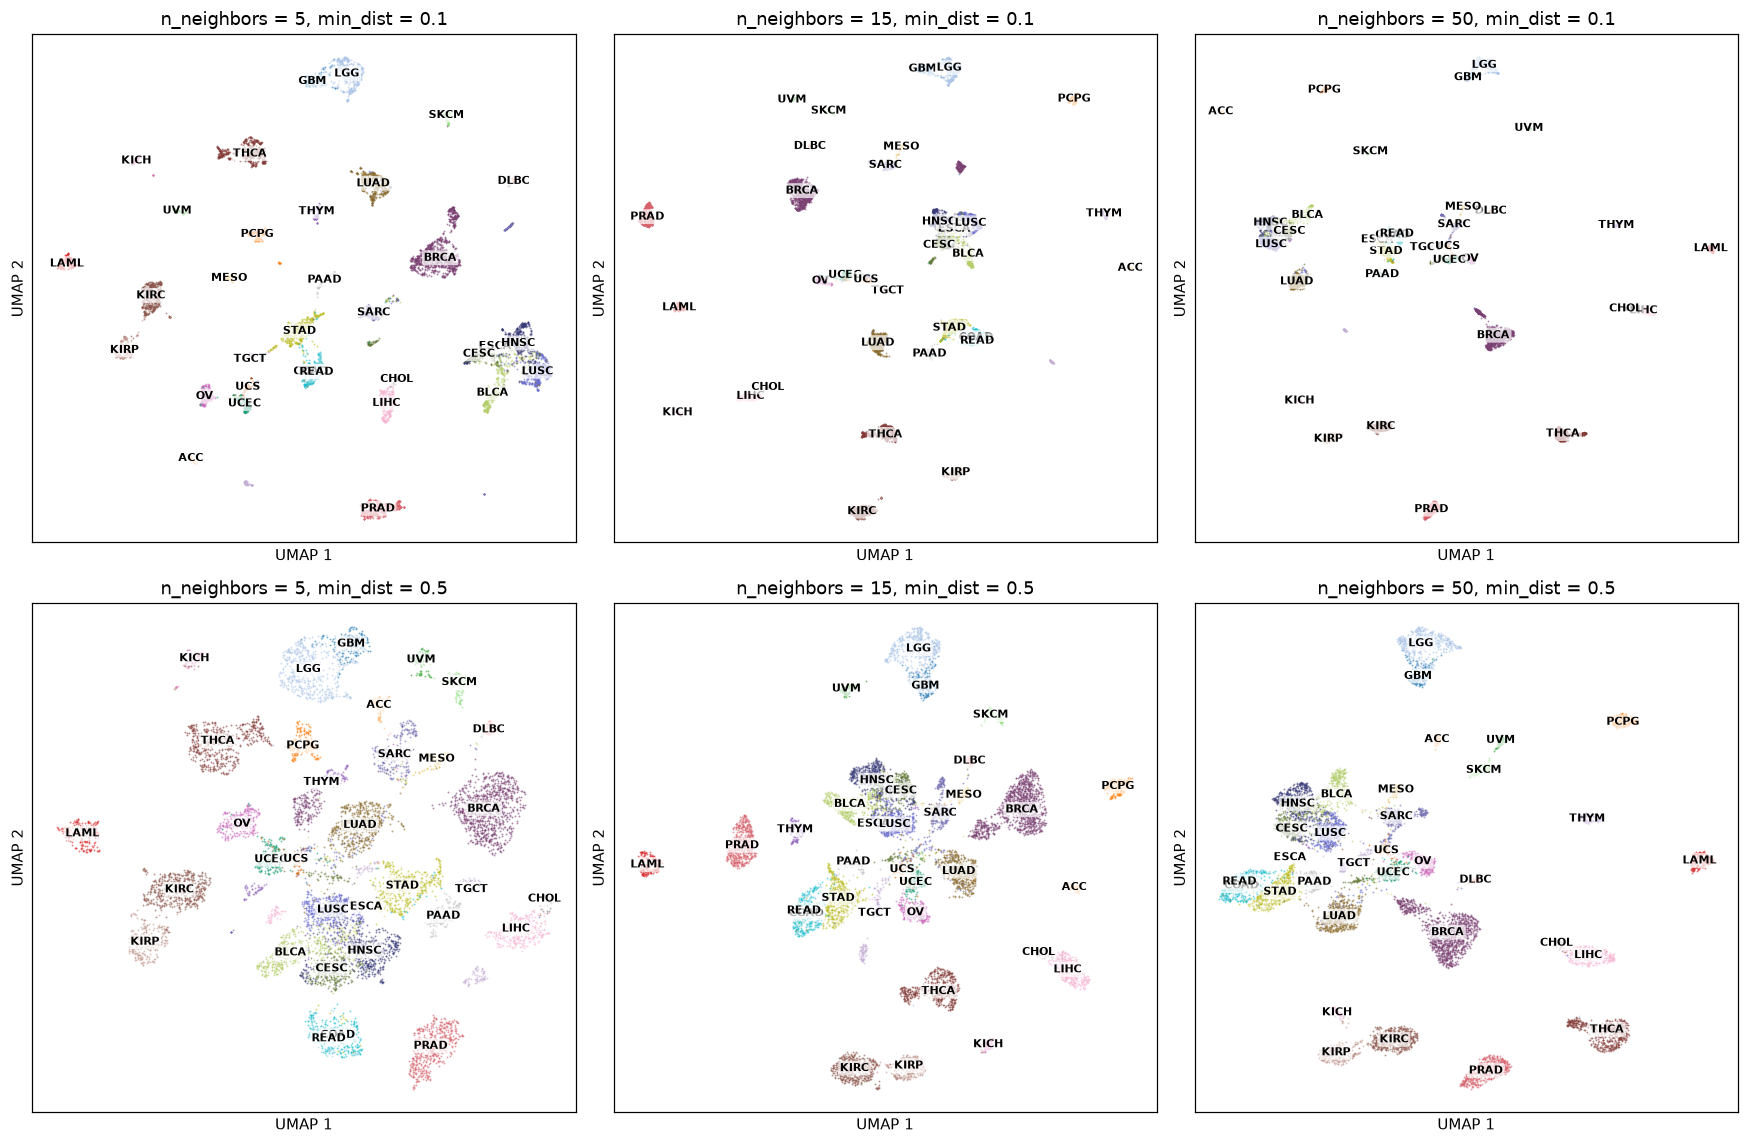

,n_neighbors,min_dist,erhaltene Nachbarn,Anteil eigener Typ
0,5,0.1,0.387,0.831
1,5,0.5,0.364,0.822
2,15,0.1,0.375,0.826
3,15,0.5,0.352,0.818
4,50,0.1,0.333,0.826
5,50,0.5,0.325,0.817


In [12]:
varianten = [(k, d) for k in [5, 15, 50] for d in [0.1, 0.5]]
einbettungen, zeilen = {}, []
for k, d in varianten:
    Ei = E if (k, d) == (15, 0.5) else umap_2d(Y, n_neighbors=k, min_dist=d)
    einbettungen[(k, d)] = Ei
    nb_i = nachbarn(Ei)
    zeilen.append({"n_neighbors": k, "min_dist": d, "erhaltene Nachbarn": erhalten(nb_pca, nb_i), "Anteil eigener Typ": eigener_anteil(nb_i).mean()})
robust_param = pd.DataFrame(zeilen)

fig, axes = plt.subplots(2, 3, figsize=(16, 10.5))
for ax, (k, d) in zip(axes.T.ravel(), varianten):
    umap_bild(ax, einbettungen[(k, d)], f"n_neighbors = {k}, min_dist = {d}", s=1.5)
plt.tight_layout()
plt.show()
robust_param.round(3)

**Beobachtungen:**
- Die Maße ändern sich kaum: erhaltene Nachbarn zwischen 33 % und 39 %, Anteil eigener Typ zwischen 82 % und 83 %.
  Kleine Nachbarschaften (`n_neighbors = 5`) und kleines `min_dist` erhalten etwas mehr lokale Nachbarn.
- Die **Bilder** sehen dagegen sehr verschieden aus: Mit `min_dist = 0,1` schrumpfen die Tumortypen zu kleinen Inseln, mit `n_neighbors = 5` zerfällt das Bild in viele Stücke.
  Welche Tumortypen zusammenliegen, bleibt aber in allen sechs Bildern gleich (zum Beispiel Plattenepithelkarzinome, Verdauungstrakt, Niere, Hirntumoren).
- Die **Lage** der Gruppen zueinander ändert sich von Bild zu Bild; sie ist nicht deutbar.

### 5.2 Eingabe: 20 oder 50 Hauptkomponenten oder alle 5.000 Gene

Gemessen wird immer gegen die Nachbarschaft in der **jeweiligen** Eingabe. Ab etwa Hauptkomponente 8 enthalten die Achsen einen kleinen Plattenanteil
(siehe `notebook_aufbereitung.ipynb`); mit 20 Hauptkomponenten fließt davon weniger ein.

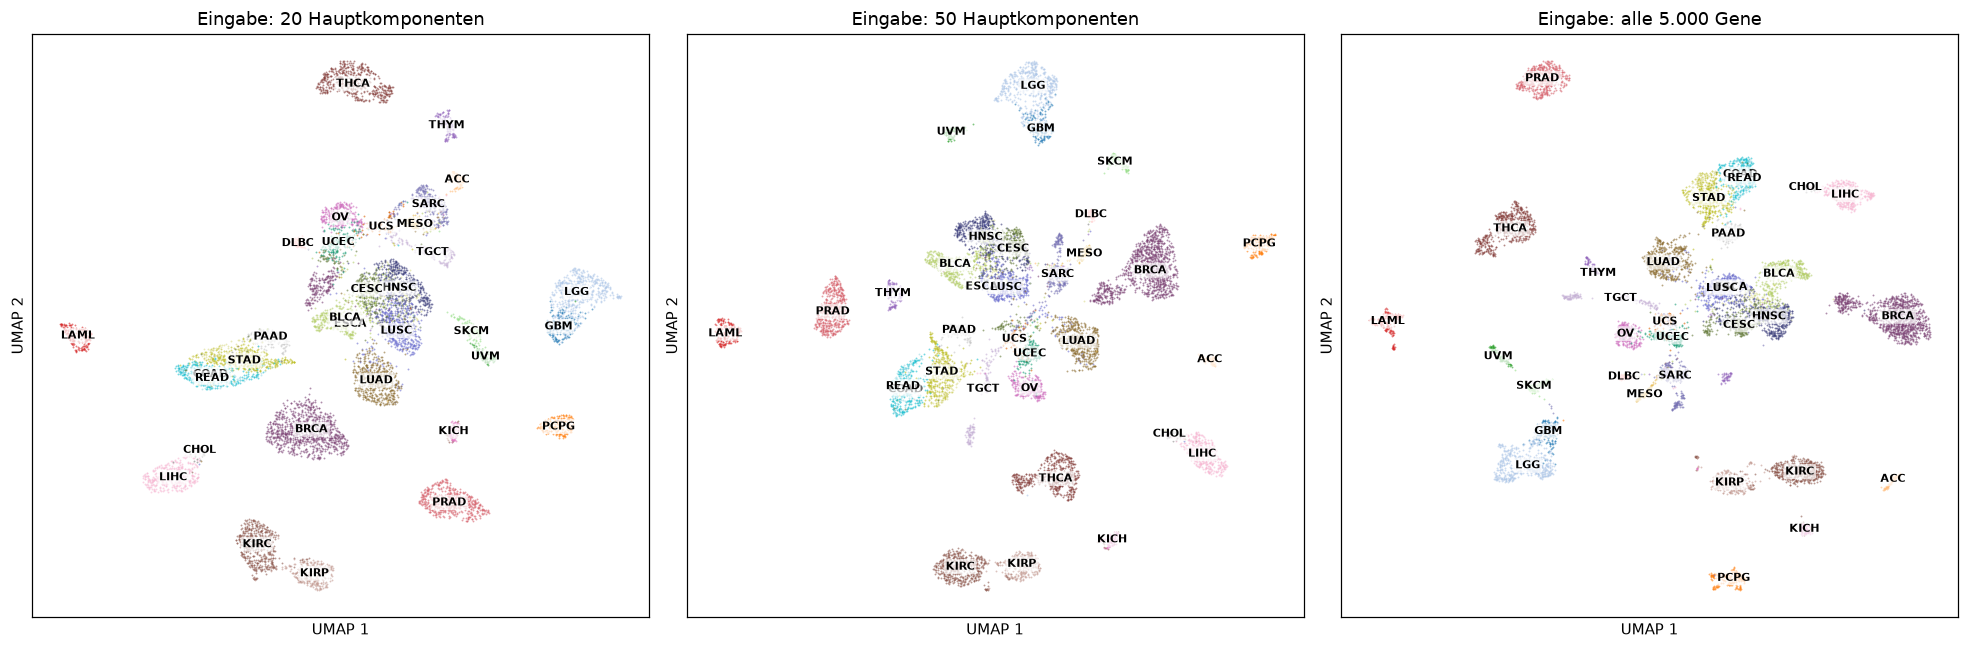

,Anteil eigener Typ (Eingabe),erhaltene Nachbarn,Anteil eigener Typ (UMAP-Bild)
Eingabe,,,
20 Hauptkomponenten,0.804,0.357,0.785
50 Hauptkomponenten,0.841,0.352,0.818
alle 5.000 Gene,0.852,0.288,0.829


In [13]:
X_gene = np.load(DATA_DIR / "aufbereitet_matrix.npy")                 # Proben × 5.000 Gene, zentriert
eingaben = {"20 Hauptkomponenten": Z[:, :20], "50 Hauptkomponenten": Y, "alle 5.000 Gene": X_gene}
zeilen, einb_eingabe = [], {}
for name, D in eingaben.items():
    Ei = E if name == "50 Hauptkomponenten" else umap_2d(D)
    einb_eingabe[name] = Ei
    nb_in = nb_pca if name == "50 Hauptkomponenten" else nachbarn(D)
    nb_i = nachbarn(Ei)
    zeilen.append({"Eingabe": name, "Anteil eigener Typ (Eingabe)": eigener_anteil(nb_in).mean(),
                   "erhaltene Nachbarn": erhalten(nb_in, nb_i), "Anteil eigener Typ (UMAP-Bild)": eigener_anteil(nb_i).mean()})
del X_gene
robust_eingabe = pd.DataFrame(zeilen).set_index("Eingabe")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (name, Ei) in zip(axes, einb_eingabe.items()):
    umap_bild(ax, Ei, f"Eingabe: {name}", s=1.5)
plt.tight_layout()
plt.show()
robust_eingabe.round(3)

**Beobachtungen:**
- Schon **in der Eingabe** trennen mehr Dimensionen die Tumortypen etwas besser: Anteil eigener Typ 80 % mit 20 Hauptkomponenten, 84 % mit 50, 85 % mit allen 5.000 Genen.
  Die späteren Hauptkomponenten enthalten also nicht nur Rauschen und Plattenanteile, sondern auch Unterschiede zwischen Tumortypen.
- Je mehr Dimensionen die Eingabe hat, desto weniger ihrer Nachbarschaften kann das Bild erhalten (36 %, 35 %, 29 %).
- Die Bilder zeigen dieselben Gruppen. **50 Hauptkomponenten** sind ein vernünftiger Kompromiss.

### 5.3 Zufallsstartwert

UMAP beginnt mit einer Anfangsanordnung und optimiert dann mit Zufallsstichproben. Mit einem anderen Startwert entsteht ein anderes Bild.
Lokale Nachbarschaften sollten gleich bleiben; die Lage der Gruppen zueinander kann sich ändern.

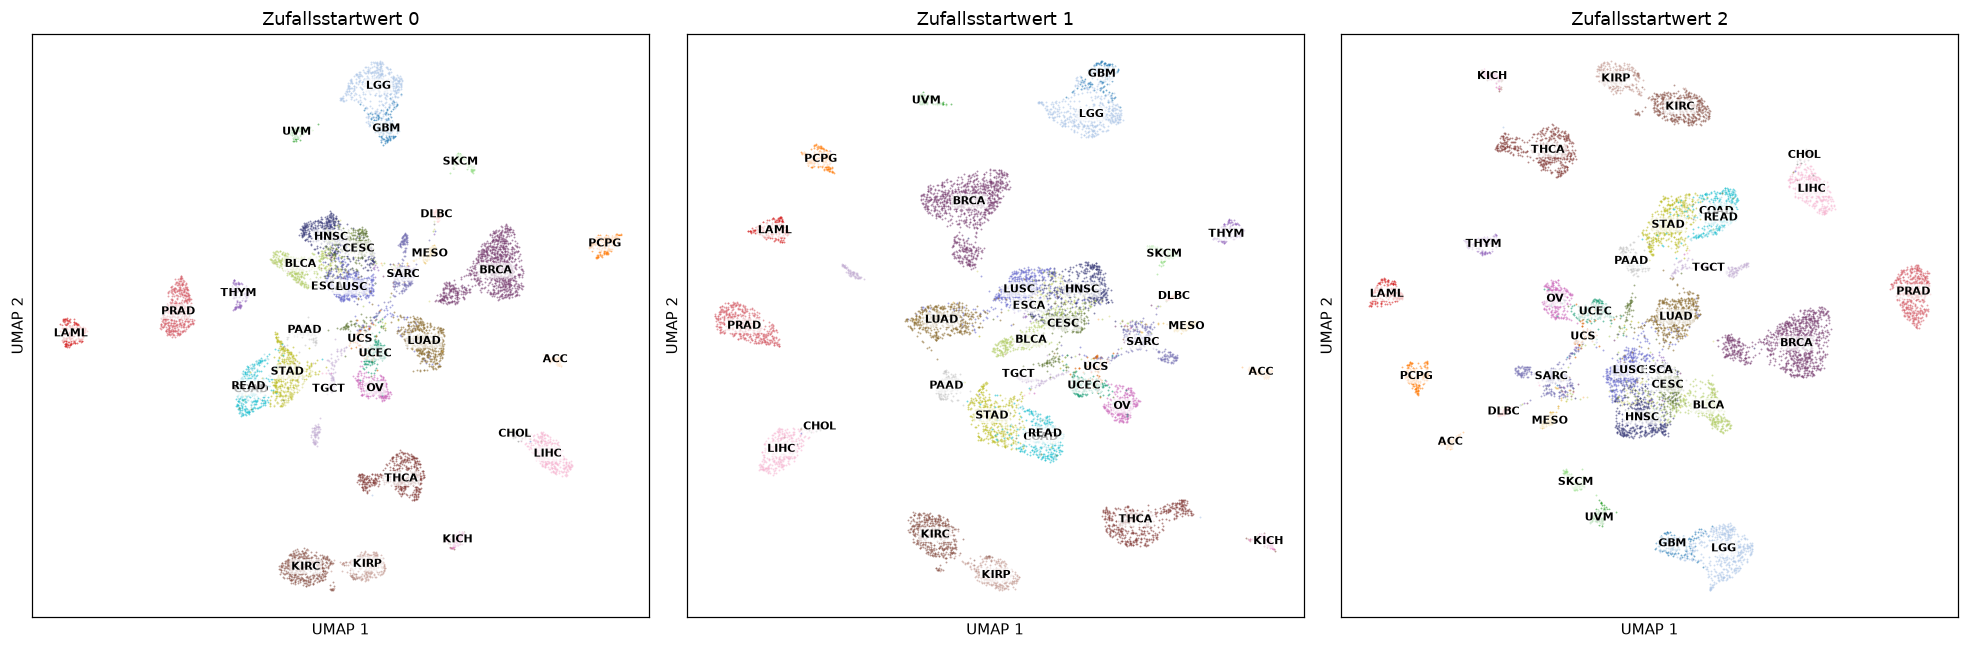

,erhaltene Nachbarn,Anteil eigener Typ,gleiche Nachbarn wie Startwert 0
Zufallsstartwert,,,
0,0.352,0.818,1.000
1,0.350,0.815,0.581
2,0.354,0.822,0.604


In [14]:
zeilen, einb_seed = [], {}
for seed in [0, 1, 2]:
    Ei = E if seed == SEED else umap_2d(Y, random_state=seed)
    einb_seed[seed] = Ei
    nb_i = nachbarn(Ei)
    zeilen.append({"Zufallsstartwert": seed, "erhaltene Nachbarn": erhalten(nb_pca, nb_i), "Anteil eigener Typ": eigener_anteil(nb_i).mean(),
                   "gleiche Nachbarn wie Startwert 0": erhalten(nb_umap, nb_i)})
robust_seed = pd.DataFrame(zeilen).set_index("Zufallsstartwert")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (seed, Ei) in zip(axes, einb_seed.items()):
    umap_bild(ax, Ei, f"Zufallsstartwert {seed}", s=1.5)
plt.tight_layout()
plt.show()
robust_seed.round(3)

**Beobachtungen:**
- Beide Maße sind für alle drei Startwerte praktisch gleich (35 % erhaltene Nachbarn, 82 % eigener Typ).
- Trotzdem sind nur **58 % bis 60 %** der Nachbarn im Bild bei verschiedenen Startwerten dieselben, und die Gruppen liegen jedes Mal woanders
  (zum Beispiel Prostata, Leber oder Brustkrebs). Das bestätigt: Die **Anordnung der Gruppen** im UMAP-Bild ist zufällig; nur die Zusammensetzung der Gruppen ist verlässlich.

## 6. Speichern

| Datei | Inhalt |
|---|---|
| `umap_2d.npy` | UMAP-Einbettung mit den Standardparametern (Proben $\times$ 2), Zeilen in der Reihenfolge von `aufbereitet_proben.csv` |
| `nachbarn_pca50.npy` | die 15 nächsten Nachbarn jeder Probe in den ersten 50 Hauptkomponenten (Zeilennummern) |

In [15]:
np.save(DATA_DIR / "umap_2d.npy", E.astype(np.float32))
np.save(DATA_DIR / "nachbarn_pca50.npy", nb_pca)
print("Gespeichert:", E.shape, nb_pca.shape)

Gespeichert: (9104, 2) (9104, 15)


## 7. Zusammenfassung und offene Fragen

**Ergebnis zur Forschungsfrage:** Die meisten Tumortypen sind in ihrer Genexpression **klar voneinander abgegrenzt** (im Mittel 84 % der Nachbarn aus dem eigenen Typ).
Wo sie sich ähneln, folgt die Ähnlichkeit dem **Gewebe**:

1. **gleiches Organ:** Dick- und Mastdarm (praktisch nicht zu unterscheiden), die beiden Hirntumoren, die Nierenkarzinome;
2. **gleicher Gewebetyp aus verschiedenen Organen:** die Plattenepithelkarzinome von Kopf-Hals, Lunge, Gebärmutterhals und Speiseröhre; die Adenokarzinome von Speiseröhre und Magen;
3. **gemeinsame Entwicklungsherkunft:** Gallengang, Leber und Bauchspeicheldrüse; die gynäkologischen Tumoren.

Mehrere Tumortypen bestehen aus **Untertypen**, die im Bild getrennt liegen. Beim Speiseröhren- und Gebärmutterhalskrebs liegen die Untertypen bei verschiedenen anderen Tumortypen:
Dort ist der histologische Typ (Plattenepithel oder Drüse) wichtiger als das Organ. Beim Brustkrebs (Östrogenrezeptor), der Schilddrüse, den Hodentumoren und dem Sarkom
bleiben die Untertypen dagegen unter sich.

**Was UMAP leistet und was nicht:**
- UMAP löst die Karzinom-Wolke der Hauptkomponentenanalyse sichtbar auf und gibt die Ähnlichkeit der Tumortypen gut wieder (82 % statt 84 % Nachbarn aus dem eigenen Typ).
- Die Nachbarschaft einzelner Proben erhält das Bild nur zu gut einem Drittel, und die Lage der Gruppen zueinander hängt vom Zufallsstartwert ab.
  Aussagen über Ähnlichkeit stützen wir deshalb auf die Nachbarschaften in den 50 Hauptkomponenten, nicht auf Abstände im Bild.

**Offene Fragen und nächste Schritte**

1. **Clustering:** Spektrales Clustering auf dem Nachbarschaftsgraphen (gespeichert in `nachbarn_pca50.npy`) und ein zweites Verfahren.
   Stimmen die Cluster mit den Tumortypen überein (bereinigter Rand-Index, *Adjusted Rand Index*), bilden die ähnlichen Paare gemeinsame Cluster,
   und finden die Verfahren die Untertypen aus Abschnitt 3.1 von selbst?
2. **Tumortypen nach Histologie trennen:** Speiseröhren- und Gebärmutterhalskrebs als je zwei Gruppen (Plattenepithel- und Adenokarzinom) behandeln? Dann verschwinden einige der „ähnlichen Paare“
   und werden durch klarere ersetzt.
3. **Nachbarschaft als Maß:** 15 Nachbarn und der euklidische Abstand sind Setzungen. Bleiben die ähnlichen Paare mit 5 oder 50 Nachbarn oder mit dem Korrelationsabstand gleich?
4. **Gruppengrößen:** Die Anteile sind nicht symmetrisch, weil große Tumortypen viele Nachbarn stellen. Ein Maß, das die Gruppengröße berücksichtigt
   (zum Beispiel Anteil geteilt durch den erwarteten Anteil), würde die Paare vergleichbarer machen.